# **Measuring Accessibility Using Python**

## **Before We Get Started...**

### **What types of data do we need?**
- **Demand Data.** Polygon or point data representing where people live and their demographic characteristics.
  - Unique identifiers.
  - Population counts.
  - *Optional:* social-economic breakdowns, ...

- **Supply Data.** Point data representing the locations of services, facilities, or amenities that people want to reach.
  - Facility type or category.
  - Capacity or weight (e.g., number of hospital beds, clinic operating hours, school enrollment size) to account for service quality or congestion.

### **Reiley's Law, Huff Model and Gravity Model**
![Gravity Model](https://raw.githubusercontent.com/XiWen0627/Tutorials2026/main/GravityModel.jpg)

- Mathematical Formulation:
$$I_{ij} = K\frac{p_ip_j}{d_{ij}^b}$$

**Reilly's law of retail gravitation**. It answers a simple question: If a smaller town lies between two larger cities, how do its residents split their shopping trips between them?
- **The Pull of Population**: Larger cities have more retail variety, higher-end goods, and greater gravitational pull, acting like "mass."
- **The Friction of Distance**: Travel cost, time, or physical distance weakens that pull (decay effect).

 Two cities draw trade from a town between them in direct proportion to their populations and in inverse proportion to the square of their distances from it.
$$ \frac{I_a}{I_b} = (\frac{P_a}{P_b})^N * (\frac{D_b}{D_a})^n$$

Where:
  - **$I_a / I_b$**: The ratio of trade volume captured by City A versus City B from the intermediate town.
  - **$P_a$** and** $P_b$**: The populations of City A and City B. (Directly proportional: higher population = more trade).
  - **$D_a$** and **$D_b$**: The distances from the intermediate town to City A and City B, respectively.

Reilly found the population exponent to be about 1 and the distance exponent to lie between 1.5 and 2.5, using 2 as the working value.

![Reilly's Law](https://raw.githubusercontent.com/XiWen0627/Tutorials2026/main/ReillyLAW.jpg)

**Huff's probability model** replaces the hard boundary with a probability surface. A shopper can go anywhere, with a chance that depends on every center on offer:
$$P_{ij} = \frac{\frac{P_j}{d_{ij}^\lambda}}{\Sigma_k(\frac{P_k}{d_{ik}^\lambda})}$$

Where:
- $P_{ij}$ is the probability of a consumer at origin $i$ visiting destination $j$.
- $P_j$ is the size, floor space, or attractiveness of center $j$.
- $d$ is the travel time or distance between $i$ and $j$.
- $λ$ is the distance-decay friction parameter, fitted by type of purchase.
- $k$ is all competing destinations available (including $j$).

**What changed:**
- Trade areas now overlap and fade.
- The model begins from individual choice rather than from aggregates.
- Attraction is measured by facility characteristics (floor space, variety, inventory) rather than the population size of the host town.

![Huff Model](https://raw.githubusercontent.com/XiWen0627/Tutorials2026/main/HuffModel.jpg)


### **Two-Step Floating Catchement Areas(2SFCA)**

The Two-Stage Floating Catchment Area (2SFCA) method is one of the most popular spatial accessibility metrics used in urban planning, geography, and public health.
It measures how well populations can access essential services (like hospitals, clinics, or parks) while explicitly accounting for service capacity and competition.
The method operates in two distinct computational steps using a "floating" buffer (catchment) around points:
- **Step 1: Supply-to-Demand Ratio**
For every supply point $j$ (e.g., a hospital), draw a catchment circle of a fixed threshold distance/time ($d_0$). Sum up all the demand (population) located within that catchment to calculate a provider-to-population ratio ($R_j$). This step accounts for congestion—a hospital surrounded by a massive population will have a lower ratio (fewer resources per person) than one in a sparsely populated area.

- **Step 2: Demand Accessibility Score**
For every demand point $i$ (e.g., a census tract centroid), draw the same catchment circle ($d_0$). Search for all supply points within reach, and sum up their provider-to-population ratios ($R_j$) calculated in Step 1. The resulting score ($A_i$) represents the total level of service accessible to that population.

![2SFCA](https://raw.githubusercontent.com/XiWen0627/Tutorials2026/main/2SFCA.jpg)

#### **Relationship with Gravity Models (Reilly' s Law & Huff's Model)**
**A. The Common Ground**
- **Distance Friction**: All of these models rely on the core principle of distance decay—that interaction or accessibility decreases as travel time, cost, or distance increases.

- **Spatial Competition**: They all recognize that individuals or towns do not exist in a vacuum; they choose among competing destinations based on proximity and attractiveness.

**B. Key Differences & Evolution**
- **Primary Focus**
  - **Gravity models** predicts where people shop or travel (probability of choice).
  - **2SFCA** measures how much service capacity a population can actually reach.
- **How Distance is handled**
  - **Gravity models** use a continuous mathematical decay curve that spans infinitely across space.
  - **2SFCA** uses a hard binary cutoff (e.g., within 60 km = full access, beyond = zero access).
- **Handling of Capacity / Congestion**
  - **Gravity models** focuses on facility size/attractiveness ($P_j$) pulling customers, but does not ration supply based on crowding.
  - **2SFCA** xxplicitly rations **supply** in Step 1: if too many people rely on a single hospital, its resource score per person drops..

## **Implementation: `access` Package**
- `PySAL Spatial Access` package developed by the Centre for Spatial Data Science, University of Chicago.
- More information is shown in [Spatial Access](https://pysal.org/access/index.html).
- A brief introduction on this package is shown in [
Making Spatial Access Measurement Accessible by Julia Koschinsky](https://www.youtube.com/watch?v=MshrZc_4oVY&t=1s)

![Overview](https://raw.githubusercontent.com/XiWen0627/Tutorials2026/main/Overview.jpg)
![Workflow](https://raw.githubusercontent.com/XiWen0627/Tutorials2026/main/Workflow.jpg)


In [1]:
!pip install access

### **Step 1: Demand.**
To complete this first step, we'll need two files:
- Cook County population data at the census tract level
- Geospatial representation of Cook County Census Tracts

First, we'll load a dataset containing population counts for Cook County at the Census Tract level.

In [16]:
import numpy as np
import pandas as pd
import geopandas as gpd
from access import Access, Datasets, weights

In this tutorial, we use a sample dataset for demonstration purposes. You can easily substitute this with your own custom data.

**Important: Ensure that your dataset maintains the same schema and data types as the template.**

In [62]:
cook_county_population = Datasets.load_data("chi_pop")    # pandas.dataframe
print(f'Data type of cook_county_population {type(cook_county_population)}')
cook_county_population.head()

Data type of cook_county_population <class 'pandas.core.frame.DataFrame'>


,geoid,pop
0,17031010100,4854
1,17031010201,6450
2,17031010202,2818
3,17031010300,6236
4,17031010400,5042


Data type of cook_county_tracts <class 'geopandas.geodataframe.GeoDataFrame'>


,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geoid,geometry
0,1400000US17031440300,17,031,440300,4403,Tract,0.499,17031440300,"POLYGON ((359779.998 563694.9, 359785.854 5634..."
1,1400000US17031440600,17,031,440600,4406,Tract,0.259,17031440600,"POLYGON ((359797.31 563086.247, 359800.394 562..."
2,1400000US17031440700,17,031,440700,4407,Tract,0.126,17031440700,"POLYGON ((360201.128 563098.184, 360402.583 56..."
3,1400000US17031460200,17,031,460200,4602,Tract,0.232,17031460200,"POLYGON ((364927.536 564034.757, 365032.657 56..."
4,1400000US17031460600,17,031,460600,4606,Tract,0.101,17031460600,"POLYGON ((364641.501 563219.094, 364699.974 56..."


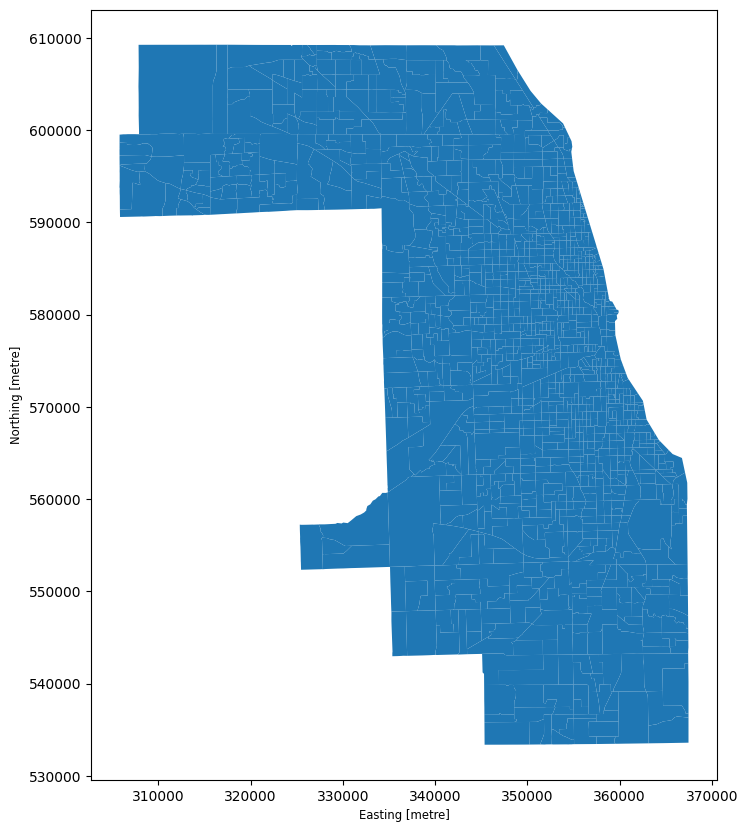

In [63]:
cook_county_tracts = Datasets.load_data("cook_county_tracts")    # geo dataframe
print(f'Data type of cook_county_tracts {type(cook_county_tracts)}')

# Visualization
cook_county_tracts.plot(figsize=(10, 10))
cook_county_tracts.head()

Now we will join the geospatial representations of Cook County Tracts to the population data and plot the population numbers so that we can see the differences at the tract level.

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geoid,geometry,pop
0,1400000US17031440300,17,031,440300,4403,Tract,0.499,17031440300,"POLYGON ((359779.998 563694.9, 359785.854 5634...",4757
1,1400000US17031440600,17,031,440600,4406,Tract,0.259,17031440600,"POLYGON ((359797.31 563086.247, 359800.394 562...",2080
2,1400000US17031440700,17,031,440700,4407,Tract,0.126,17031440700,"POLYGON ((360201.128 563098.184, 360402.583 56...",1545
3,1400000US17031460200,17,031,460200,4602,Tract,0.232,17031460200,"POLYGON ((364927.536 564034.757, 365032.657 56...",2385
4,1400000US17031460600,17,031,460600,4606,Tract,0.101,17031460600,"POLYGON ((364641.501 563219.094, 364699.974 56...",1183


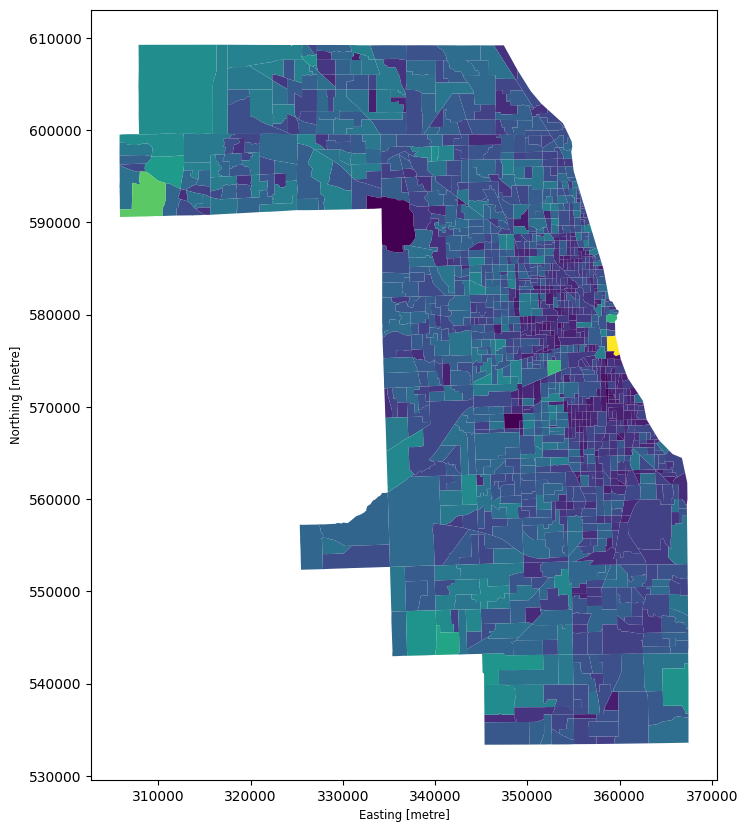

In [5]:
cook_county_geopop = cook_county_tracts.merge(cook_county_population, on="geoid")
cook_county_geopop.plot(column="pop", figsize=(10, 10))
cook_county_geopop.head()

### **Step 2: Supply.**

Next up, we will load the hospital data which has an XY coordinate pair for each hospital. Using the XY coordinates, we will create geospatial points which can then be used to calculate the distances between the cencus tracts and hospitals.

You can also directly load you own point data using `gpd.read_file()`

In [7]:
cook_county_hospitals = Datasets.load_data("cook_county_hospitals")     # pandas.dataframe
cook_county_hospitals.head()

,ADDRESS,CFNAME,CFSUBTYPE,CFTYPE,Community,GNISCODE,Jurisdicti,OBJECTID,SOURCE,COORD_X,COORD_Y
0,9340 S Kostner Ave,Advocate Christ Medical Center,Hospital,Hospital,Oak Lawn,426825.0,NaN,1,CGI,-87.732438,41.722202
1,15300 West Ave,Palos Primary Care Center,Hospital,Hospital,Orland Park,2036658.0,NaN,2,CL,-87.865552,41.610533
2,15901 Cicero Ave,Oak Forest Hospital,Hospital,Hospital,Bremen Twp,414760.0,NaN,3,CEGL,-87.731486,41.599667
3,375 W North Ave,Gottlieb Memorial Hospital,Hospital,Hospital,Melrose Park,409212.0,NaN,4,BCEG,-87.843465,41.910779
4,2100 Pfingsten Rd,Glenbrook Hospital,Hospital,Hospital,Glenview,2033578.0,NaN,5,CEGI,-87.851615,42.092630


In [8]:
cook_county_hospitals_geom = gpd.GeoDataFrame(
    cook_county_hospitals,
    geometry=gpd.points_from_xy(
        cook_county_hospitals.COORD_X, cook_county_hospitals.COORD_Y
    ),
)
cook_county_hospitals_geom.head()

,ADDRESS,CFNAME,CFSUBTYPE,CFTYPE,Community,GNISCODE,Jurisdicti,OBJECTID,SOURCE,COORD_X,COORD_Y,geometry
0,9340 S Kostner Ave,Advocate Christ Medical Center,Hospital,Hospital,Oak Lawn,426825.0,NaN,1,CGI,-87.732438,41.722202,POINT (-87.73244 41.7222)
1,15300 West Ave,Palos Primary Care Center,Hospital,Hospital,Orland Park,2036658.0,NaN,2,CL,-87.865552,41.610533,POINT (-87.86555 41.61053)
2,15901 Cicero Ave,Oak Forest Hospital,Hospital,Hospital,Bremen Twp,414760.0,NaN,3,CEGL,-87.731486,41.599667,POINT (-87.73149 41.59967)
3,375 W North Ave,Gottlieb Memorial Hospital,Hospital,Hospital,Melrose Park,409212.0,NaN,4,BCEG,-87.843465,41.910779,POINT (-87.84347 41.91078)
4,2100 Pfingsten Rd,Glenbrook Hospital,Hospital,Hospital,Glenview,2033578.0,NaN,5,CEGI,-87.851615,42.092630,POINT (-87.85161 42.09263)


Plot the demand and supply datasets together in a single figure.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

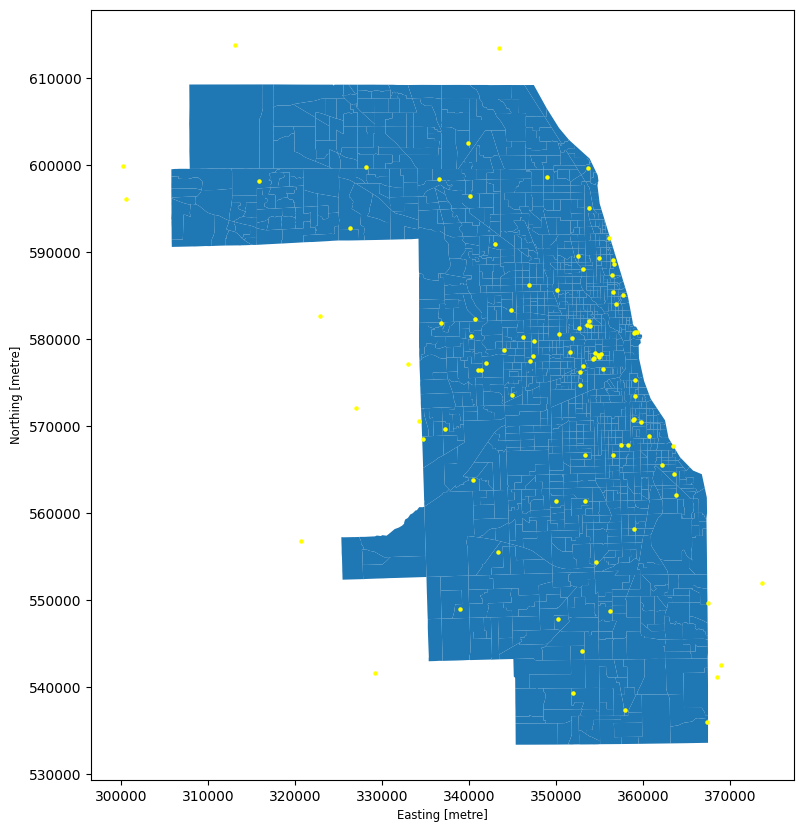

In [9]:
cook_county_hospitals_geom = cook_county_hospitals_geom.set_crs(4326)
cook_county_hospitals_geom = cook_county_hospitals_geom.to_crs(epsg=3528)

base = cook_county_tracts.plot(figsize=(10, 10))
cook_county_hospitals_geom.plot(ax=base, color="yellow", markersize=5, figsize=(10, 10))

Having created a geometric representation of each hospital, we can now perform a spatial join between the newly created points and the census tracts to bring in the geoid of the Census Tract the hospital is in.

In the next step, we reassign the CRS to the `cook_county_hospitals_geom` dataframe, perform the spatial join, drop a column, and view the newly joined geoid column showing **the Census Tract that the hospital is located in**.

In [10]:
cook_county_hospitals_geom = cook_county_hospitals_geom.set_crs(3528)
cook_county_hospitals_w_tracts = gpd.sjoin(
    cook_county_hospitals_geom,
    cook_county_tracts[["geoid", "geometry"]],
    how="inner",
    predicate="intersects",
)
cook_county_hospitals_w_tracts = cook_county_hospitals_w_tracts.drop(
    columns=["index_right"]
)
cook_county_hospitals_w_tracts.head()

,ADDRESS,CFNAME,CFSUBTYPE,CFTYPE,Community,GNISCODE,Jurisdicti,OBJECTID,SOURCE,COORD_X,COORD_Y,geometry,geoid
0,9340 S Kostner Ave,Advocate Christ Medical Center,Hospital,Hospital,Oak Lawn,426825.0,NaN,1,CGI,-87.732438,41.722202,POINT (349999.428 561422.673),17031822102
1,15300 West Ave,Palos Primary Care Center,Hospital,Hospital,Orland Park,2036658.0,NaN,2,CL,-87.865552,41.610533,POINT (338990.545 548951.525),17031824116
2,15901 Cicero Ave,Oak Forest Hospital,Hospital,Hospital,Bremen Twp,414760.0,NaN,3,CEGL,-87.731486,41.599667,POINT (350173.71 547813.914),17031825200
3,375 W North Ave,Gottlieb Memorial Hospital,Hospital,Hospital,Melrose Park,409212.0,NaN,4,BCEG,-87.843465,41.910779,POINT (340641.61 582308.963),17031811302
4,2100 Pfingsten Rd,Glenbrook Hospital,Hospital,Hospital,Glenview,2033578.0,NaN,5,CEGI,-87.851615,42.092630,POINT (339851.861 602503.437),17031801607


### **Step 3: Cost.**

Here we use euclidean distance. You can also use pre-computed cost matrix. See [this tutorial](https://nbviewer.org/github/pysal/access/blob/main/notebooks/2_subset_travel_cost_matrices.ipynb).

**You can load pre-computed cost matrix at this step in after-class exercise**.

In [64]:
# Get centroids on the fly from the geometry column
tract_centroids = cook_county_tracts.geometry.centroid

# Build an OD (Origin-Destination) list
od_data = []

for i, tract_row in cook_county_tracts.iterrows():
    origin_id = tract_row['geoid']  # Demand tract GEOID
    tract_geom = tract_centroids.loc[i]

    for j, hosp_row in cook_county_hospitals_w_tracts.iterrows():
        dest_id = hosp_row['geoid']  # Hospital GEOID / ID (change column name if different)
        hosp_geom = hosp_row.geometry

        # Calculate distance in original units (assumes meters if using a projected CRS like UTM/State Plane)
        dist_meters = tract_geom.distance(hosp_geom)

        # Avoid zero division or overlapping points
        dist_meters = max(dist_meters, 1.0)

        # Convert meters to kilometers
        cost_km = dist_meters / 1000.0

        od_data.append({
            'origin': origin_id,
            'dest': dest_id,
            'cost': cost_km
        })

# Convert to a pandas DataFrame
od_df = pd.DataFrame(od_data)

# Preview the result
od_df.head()

,origin,dest,cost
0,17031440300,17031822102,9.693187
1,17031440300,17031824116,25.269468
2,17031440300,17031825200,18.519545
3,17031440300,17031811302,26.273696
4,17031440300,17031801607,43.271312


###**Step 4.: Calculate Accessible Measures Using Cost Matrix**

#### **Method 1: Gravity Model**

We can directly use `access` package to measure accessibility.

To calculate a gravity score, we must first define a gravity weight function. Once we've defined our weight function, we can pass that as an argument to the access.`weighted_catchment()` method. After calling the method, you'll see access score output.

In [65]:
cook_hospital_access_dis = Access(
    demand_df=cook_county_geopop,
    demand_index="geoid",    # Unique ID column for demand polygons
    demand_value="pop",    # Column containing population count
    supply_df=cook_county_hospitals_w_tracts,
    supply_index="geoid",    # Unique ID column for supply points
    cost_df=od_df,          # This column should be different
    cost_origin="origin",    # cost matrix
    cost_dest="dest",
    cost_name="cost",
)

access INFO     :: Warning: A supply value was not provided, so a default
                             supply value of 1 was created in the column named "value".
                             Note that without a supply value, you cannot use any of the
                             floating catchment area methods.


In [66]:
# Gravity Wieght Function
# Input: distance x
# Output: a decay weight between 0 and 1 based on the inverse power relationship.
gravity = weights.gravity(scale=60, alpha=-1)
cook_hospital_access_dis.weighted_catchment(name="gravity", weight_fn=gravity)

,gravity_value
geoid,
17031010100,483.709493
17031010201,508.900167
17031010202,496.298875
17031010300,484.867564
17031010400,539.718060
...,...
17031843700,754.473728
17031843800,792.110943
17031843900,628.507594


Now, we'll plot our gravity score.

In [73]:
cook_map = (
        cook_county_geopop[["geoid", "geometry"]]
        .set_index("geoid")
        .join(cook_hospital_access_dis.access_df, how="inner")
    )    # A spatial table that contains both the geographic shapes and the accessibility metrics
cook_map.head(5)

,geometry,pop,gravity_value
geoid,,,
17031440300,"POLYGON ((359779.998 563694.9, 359785.854 5634...",4757,519.751487
17031440600,"POLYGON ((359797.31 563086.247, 359800.394 562...",2080,480.017679
17031440700,"POLYGON ((360201.128 563098.184, 360402.583 56...",1545,484.570405
17031460200,"POLYGON ((364927.536 564034.757, 365032.657 56...",2385,439.051527
17031460600,"POLYGON ((364641.501 563219.094, 364699.974 56...",1183,478.629074


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

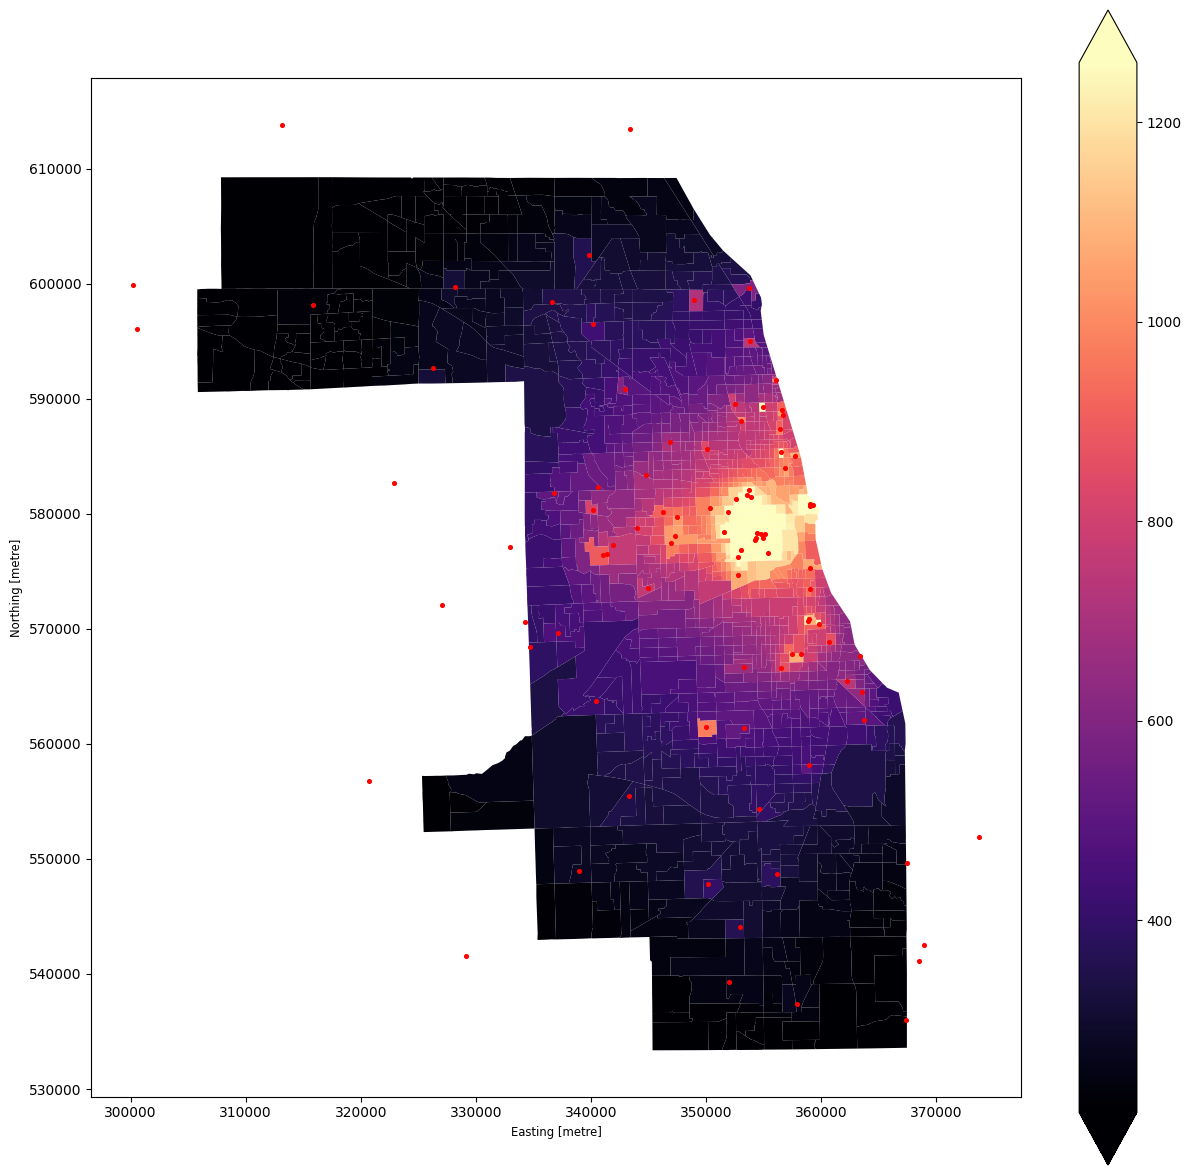

In [74]:
base = cook_map.plot(
        "gravity_value",
        legend=True,
        figsize=(15, 15),
        cmap="magma",
        markersize=0.5,
        alpha=1,
        vmin=cook_map["gravity_value"].quantile(0.05),
        vmax=cook_map["gravity_value"].quantile(0.95),
    )
cook_county_hospitals_geom.plot(ax=base, markersize=7, color="red")

#### **Method 2. Floating Catchment Areas(FCA) and Two-Step FCAs (2SFCA)**

- The 2SFCA model explicitly incorporates supply capacity attributes. In this step, we synthesize a 'beds' column to serve as a proxy for hospital capacity.

- Later, you can replace `cook_county_hospitals_w_tracts` with your own dataset containing actual facility capacity attributes.


In [39]:
# Generate random integer bed counts between 100 and 1000 for each hospital
cook_county_hospitals_w_tracts['beds'] = np.random.randint(
    low=100,
    high=1000,
    size=len(cook_county_hospitals_w_tracts)
)
cook_county_hospitals_w_tracts.head(10)

,ADDRESS,CFNAME,CFSUBTYPE,CFTYPE,Community,GNISCODE,Jurisdicti,OBJECTID,SOURCE,COORD_X,COORD_Y,geometry,geoid,beds
0,9340 S Kostner Ave,Advocate Christ Medical Center,Hospital,Hospital,Oak Lawn,426825.0,NaN,1,CGI,-87.732438,41.722202,POINT (349999.428 561422.673),17031822102,197
1,15300 West Ave,Palos Primary Care Center,Hospital,Hospital,Orland Park,2036658.0,NaN,2,CL,-87.865552,41.610533,POINT (338990.545 548951.525),17031824116,235
2,15901 Cicero Ave,Oak Forest Hospital,Hospital,Hospital,Bremen Twp,414760.0,NaN,3,CEGL,-87.731486,41.599667,POINT (350173.71 547813.914),17031825200,460
3,375 W North Ave,Gottlieb Memorial Hospital,Hospital,Hospital,Melrose Park,409212.0,NaN,4,BCEG,-87.843465,41.910779,POINT (340641.61 582308.963),17031811302,683
4,2100 Pfingsten Rd,Glenbrook Hospital,Hospital,Hospital,Glenview,2033578.0,NaN,5,CEGI,-87.851615,42.092630,POINT (339851.861 602503.437),17031801607,340
5,2739 S Sacramento Ave,Cermak Hospital,Hospital,Hospital,Chicago,2673936.0,NaN,6,CEG,-87.697866,41.841497,POINT (352778.229 574693.049),17031843500,610
6,5720 W Roosevelt Rd,Hartgrove Hospital,Hospital,Hospital,Chicago,1832957.0,NaN,7,C,-87.767409,41.866515,POINT (346984.055 577431.408),17031831400,392
7,3238 W Franklin Blvd,Sacred Heart Hospital,Hospital,Hospital,Chicago,1826901.0,NaN,8,C,-87.708234,41.890620,POINT (351877.404 580142.813),17031836700,229
8,2233 W Division St,Saint Mary Of Nazareth Hospital,Hospital,Hospital,Chicago,417534.0,NaN,9,BCG,-87.683341,41.902149,POINT (353933.58 581438.672),17031242400,468
9,1432 N Oakley Blvd,Saint Elizabeth's Hospital,Hospital,Hospital,Chicago,417267.0,NaN,10,BCGE,-87.685322,41.907445,POINT (353764.732 582025.651),17031241200,369


In [71]:
cook_hospital_access_2SFCA = Access(
    demand_df=cook_county_geopop,
    demand_index="geoid",
    demand_value="pop",
    supply_df=cook_county_hospitals_w_tracts,
    supply_index="geoid",
    supply_value = "beds",    # New input for 2SFCA
    cost_df=od_df,
    cost_origin="origin",
    cost_dest="dest",
    cost_name="cost",
)

- **Inside the Catchment ($\le 60$ km)**: Every hospital is given a full weight of 1.0 (no distance decay; a hospital 1 km away is treated the exact same as a hospital 59 km away).
- **Outside the Catchment ($> 60$ km)**: The weight drops instantly to 0.

In [72]:
cook_hospital_access_2SFCA.two_stage_fca(name="standard_2sfca", max_cost=60)

,standard_2sfca_beds
geoid,
17031010100,0.009297
17031010201,0.009297
17031010202,0.009297
17031010300,0.009297
17031010400,0.009297
...,...
17031843700,0.009297
17031843800,0.009297
17031843900,0.009297


In [75]:
cook_map_2SFCA = (
        cook_county_geopop[["geoid", "geometry"]]
        .set_index("geoid")
        .join(cook_hospital_access_2SFCA.access_df, how="inner")
    )    # A spatial table that contains both the geographic shapes and the accessibility metrics
cook_map_2SFCA.head(5)

,geometry,pop,standard_2sfca_beds
geoid,,,
17031440300,"POLYGON ((359779.998 563694.9, 359785.854 5634...",4757,0.009297
17031440600,"POLYGON ((359797.31 563086.247, 359800.394 562...",2080,0.009297
17031440700,"POLYGON ((360201.128 563098.184, 360402.583 56...",1545,0.009297
17031460200,"POLYGON ((364927.536 564034.757, 365032.657 56...",2385,0.009212
17031460600,"POLYGON ((364641.501 563219.094, 364699.974 56...",1183,0.009297


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

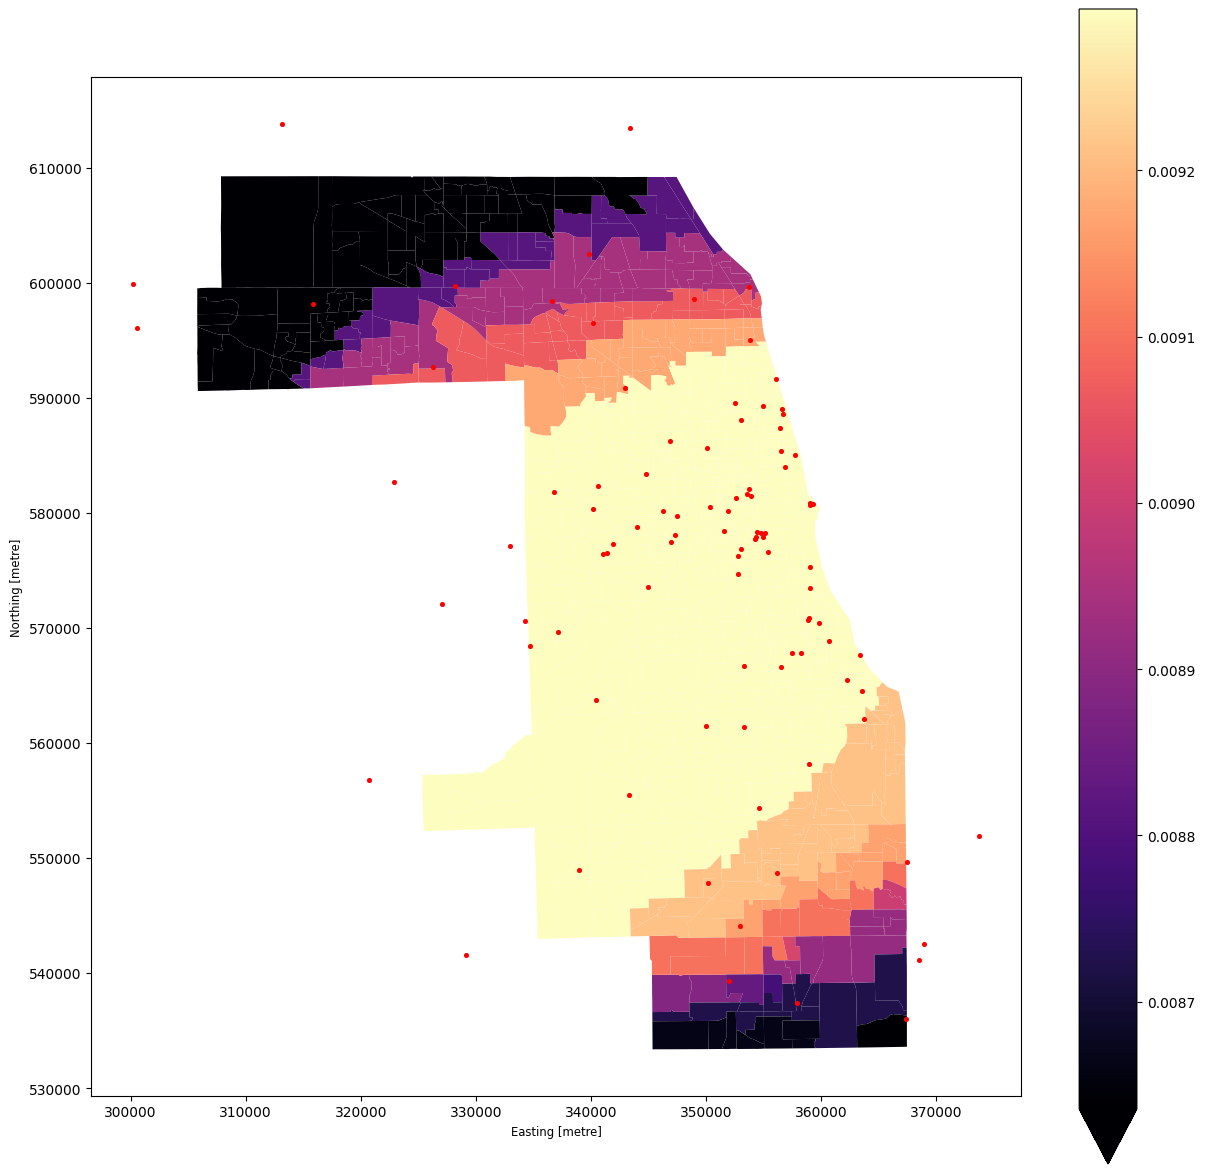

In [80]:
base_2SFCA = cook_map_2SFCA.plot(
    "standard_2sfca_beds",
    legend=True,
    figsize=(15, 15),
    cmap="magma",
    markersize=0.5,
    alpha=1,
    vmin=cook_map_2SFCA["standard_2sfca_beds"].quantile(0.05),
    vmax=cook_map_2SFCA["standard_2sfca_beds"].quantile(0.95),
    )
cook_county_hospitals_geom.plot(ax=base_2SFCA, markersize=7, color="red")

### **Step 5: Saving Access Measures to a CSV.**

In [61]:
cook_hospital_access_dis.access_df.head(10)
cook_hospital_access_dis.access_df.to_csv(r'./accessibility_measure.csv')

In [60]:
cook_hospital_access_2SFCA.access_df.head(10)
cook_hospital_access_2SFCA.access_df.to_csv(r'./accessibility_2SFCA.csv')


## **After-Class Exercise**
Try to use pre-computed travel time as cost matrix at **step 3**.

```
# Load cost matrix
cook_cost_matrix = Datasets.load_data("chi_times")
cook_cost_matrix.head()
```
